<a href="https://colab.research.google.com/github/dnanaat/PCVK_Genap_2026/blob/main/Week07_09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


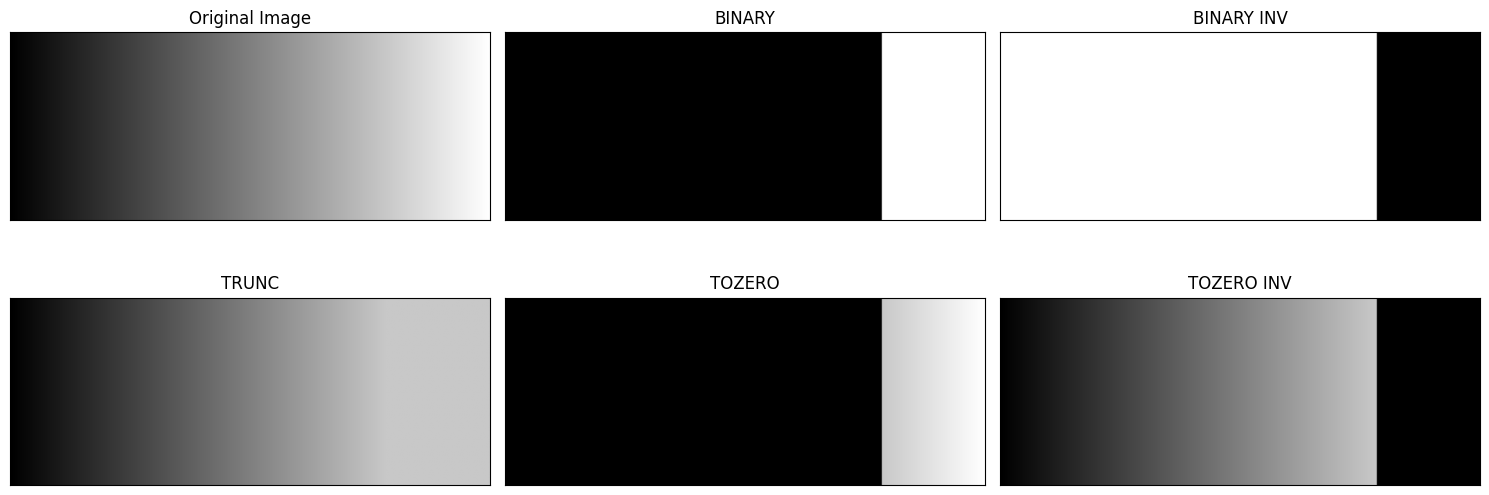

In [10]:
#NOMOR 3

# Membaca citra gradient (atau citra grayscale lainnya)
filename = '/content/drive/MyDrive/PCVK/Images/gradient.jpg'
img = cv.imread(filename, 0)
if img is None:
    # Fallback sintetis jika file belum ada
    img = np.tile(np.linspace(0, 255, 256, dtype=np.uint8), (100, 1))

thresh = 200
maxval = 255

# 1. BINARY: jika piksel > thresh -> maxval, selain itu -> 0
th_binary = np.where(img > thresh, maxval, 0).astype(np.uint8)

# 2. BINARY_INV: jika piksel > thresh -> 0, selain itu -> maxval
th_binary_inv = np.where(img > thresh, 0, maxval).astype(np.uint8)

# 3. TRUNC: jika piksel > thresh -> thresh, selain itu -> tetap
th_trunc = np.where(img > thresh, thresh, img).astype(np.uint8)

# 4. TOZERO: jika piksel > thresh -> tetap, selain itu -> 0
th_tozero = np.where(img > thresh, img, 0).astype(np.uint8)

# 5. TOZERO_INV: jika piksel > thresh -> 0, selain itu -> tetap
th_tozero_inv = np.where(img > thresh, 0, img).astype(np.uint8)

titles = ['Original Image', 'BINARY', 'BINARY INV', 'TRUNC', 'TOZERO', 'TOZERO INV']
images = [img, th_binary, th_binary_inv, th_trunc, th_tozero, th_tozero_inv]

plt.figure(figsize=(15, 6))
for i in range(len(images)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

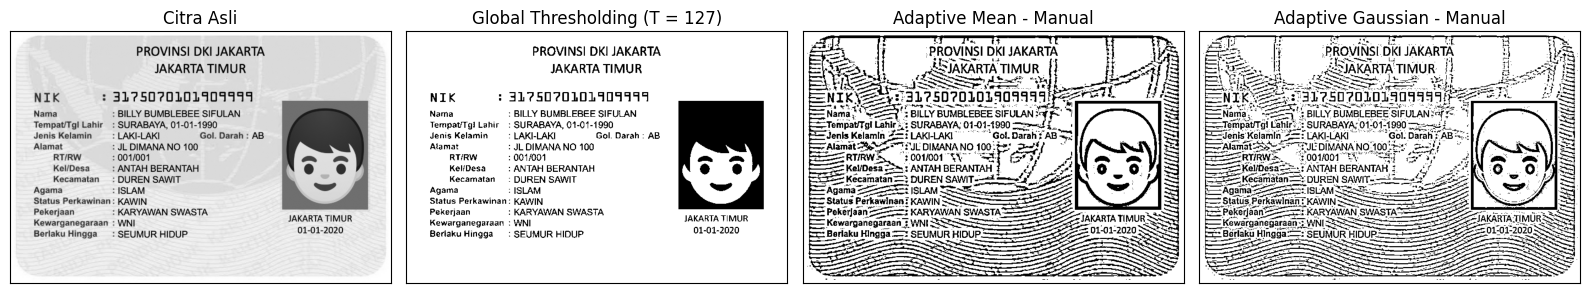

In [7]:
#NOMOR 4

filename = '/content/drive/MyDrive/PCVK/ktpcontoh.jpeg'
citra = cv.imread(filename, 0)

# Parameter praktikum
b = 11      # Window size 11x11
C = 2       # Konstanta C
sigma = 2   # Standar deviasi kernel Gaussian
pad = b // 2
H, W = citra.shape

# 1. Global Thresholding Manual (T = 127)
th_global = np.where(citra > 127, 255, 0).astype(np.uint8)

# Padding citra dengan refleksi tepi
padded = np.pad(citra.astype(np.float64), pad, mode='reflect')

# 2. Adaptive Mean Manual
kernel_mean = np.ones((b, b), dtype=np.float64) / (b * b)

# 3. Adaptive Gaussian Manual: Pembentukan kernel Gaussian 2D
ax = np.arange(-pad, pad + 1)
xx, yy = np.meshgrid(ax, ax)
kernel_gauss = np.exp(-(xx**2 + yy**2) / (2.0 * sigma**2))
kernel_gauss /= np.sum(kernel_gauss)

local_mean = np.zeros((H, W), dtype=np.float64)
local_gauss = np.zeros((H, W), dtype=np.float64)

for i in range(H):
    for j in range(W):
        window = padded[i:i+b, j:j+b]
        local_mean[i, j] = np.sum(window * kernel_mean)
        local_gauss[i, j] = np.sum(window * kernel_gauss)

# Thresholding adaptif: I(x,y) > (T_lokal - C) -> 255, else -> 0
th_adapt_mean = np.where(citra > (local_mean - C), 255, 0).astype(np.uint8)
th_adapt_gauss = np.where(citra > (local_gauss - C), 255, 0).astype(np.uint8)

titles_adapt = ['Citra Asli', 'Global Thresholding (T = 127)', 'Adaptive Mean - Manual', 'Adaptive Gaussian - Manual']
images_adapt = [citra, th_global, th_adapt_mean, th_adapt_gauss]

plt.figure(figsize=(16, 4))
for i in range(4):
    plt.subplot(1, 4, i + 1)
    plt.imshow(images_adapt[i], cmap='gray')
    plt.title(titles_adapt[i])
    plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

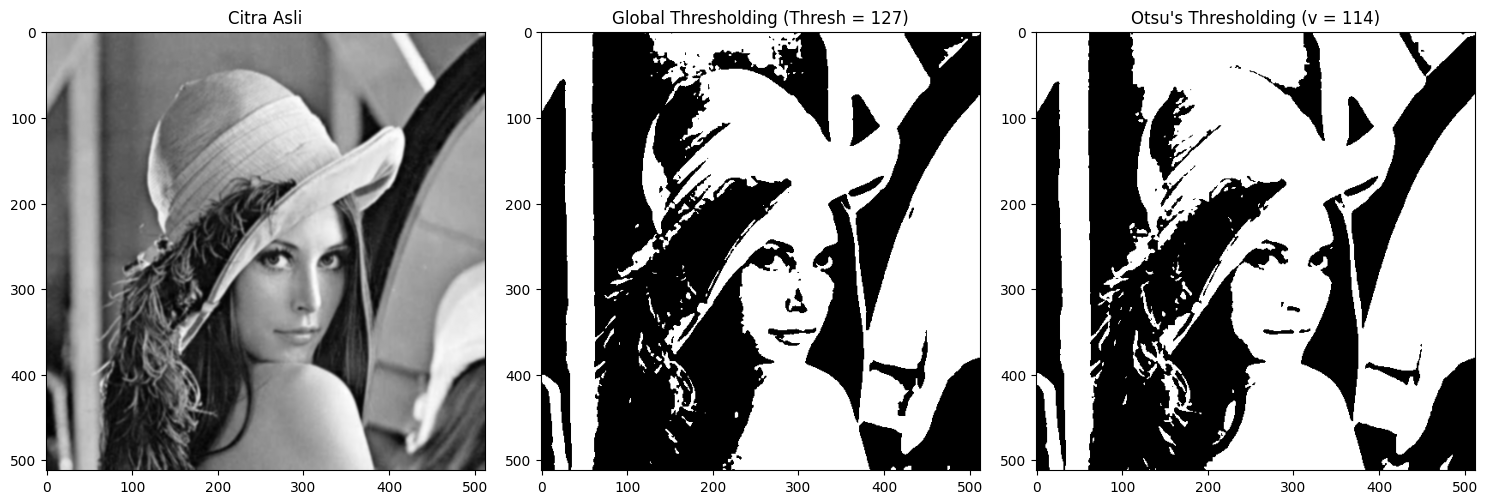

In [9]:
#NOMOR 5

def manual_otsu(gray):
    total_pixels = gray.size
    his, bins = np.histogram(gray, bins=np.arange(257))

    final_thresh = -1
    max_between_var = -1.0
    intensity_arr = np.arange(256)

    for t in range(1, 256):
        # Background (class 0)
        wb_count = np.sum(his[:t])
        # Foreground (class 1)
        wf_count = np.sum(his[t:])

        if wb_count == 0 or wf_count == 0:
            continue

        Wb = wb_count / total_pixels
        Wf = wf_count / total_pixels

        mub = np.sum(intensity_arr[:t] * his[:t]) / wb_count
        muf = np.sum(intensity_arr[t:] * his[t:]) / wf_count

        # Maksimalkan Between-Class Variance
        var_between = Wb * Wf * ((mub - muf) ** 2)

        if var_between > max_between_var:
            max_between_var = var_between
            final_thresh = t

    bin_img = np.where(gray > final_thresh, 255, 0).astype(np.uint8)
    return bin_img, final_thresh

# Eksekusi pada citra Lena Low-Contrast
filename_lena = '/content/drive/MyDrive/PCVK/lena.jpeg'
img_lena = cv.imread(filename_lena, 0)
blur_lena = cv.GaussianBlur(img_lena, (5, 5), 0)

otsu_lena_bin, otsu_val_lena = manual_otsu(blur_lena)
th_global_lena = np.where(blur_lena > 127, 255, 0).astype(np.uint8)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1), plt.imshow(blur_lena, cmap='gray'), plt.title('Citra Asli')
plt.subplot(1, 3, 2), plt.imshow(th_global_lena, cmap='gray'), plt.title('Global Thresholding (Thresh = 127)')
plt.subplot(1, 3, 3), plt.imshow(otsu_lena_bin, cmap='gray'), plt.title(f"Otsu's Thresholding (v = {otsu_val_lena})")
plt.tight_layout()
plt.show()

**Jawaban Pertanyaan Analisis Lena**

**- Penyebab Global Binary bernilai 0 (hitam total):**
Citra Lena low-contrast memiliki rentang intensitas sempit yang terpusat hanya pada rentang nilai abu-abu rendah (sekitar $85$ hingga $108$). Karena seluruh nilai piksel citra berada di bawah ambang batas global T = 127 (I(x, y) <= 127), aturan biner mengubah semua piksel menjadi nilai minimum (0), sehingga layar menjadi gelap gulita.   

**- Batas Ambang yang Tepat:**
Berdasarkan penghitungan Otsu (maupun puncak pemisahan histogram), nilai ambang batas harus berada di antara nilai intensitas riil citra, yaitu di kisaran 92–93 agar objek wajah dan latar dapat terpisah dengan baik.

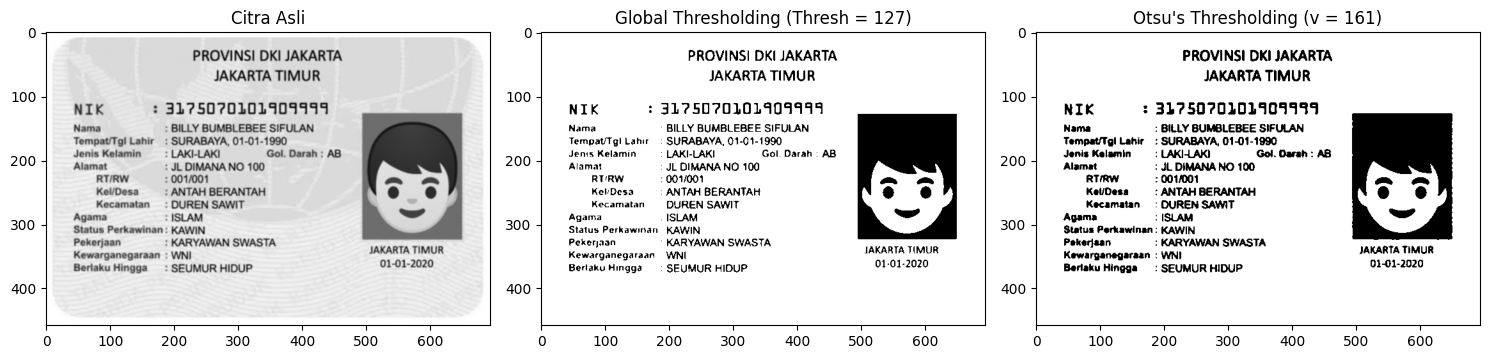

In [15]:
img_ktp = cv.imread('/content/drive/MyDrive/PCVK/ktpcontoh.jpeg', 0)
blur_ktp = cv.GaussianBlur(img_ktp, (3, 3), 0)

otsu_ktp_bin, otsu_val_ktp = manual_otsu(blur_ktp)
th_global_ktp = np.where(blur_ktp > 127, 255, 0).astype(np.uint8)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1), plt.imshow(blur_ktp, cmap='gray'), plt.title('Citra Asli')
plt.subplot(1, 3, 2), plt.imshow(th_global_ktp, cmap='gray'), plt.title('Global Thresholding (Thresh = 127)')
plt.subplot(1, 3, 3), plt.imshow(otsu_ktp_bin, cmap='gray'), plt.title(f"Otsu's Thresholding (v = {otsu_val_ktp})")
plt.tight_layout()
plt.show()

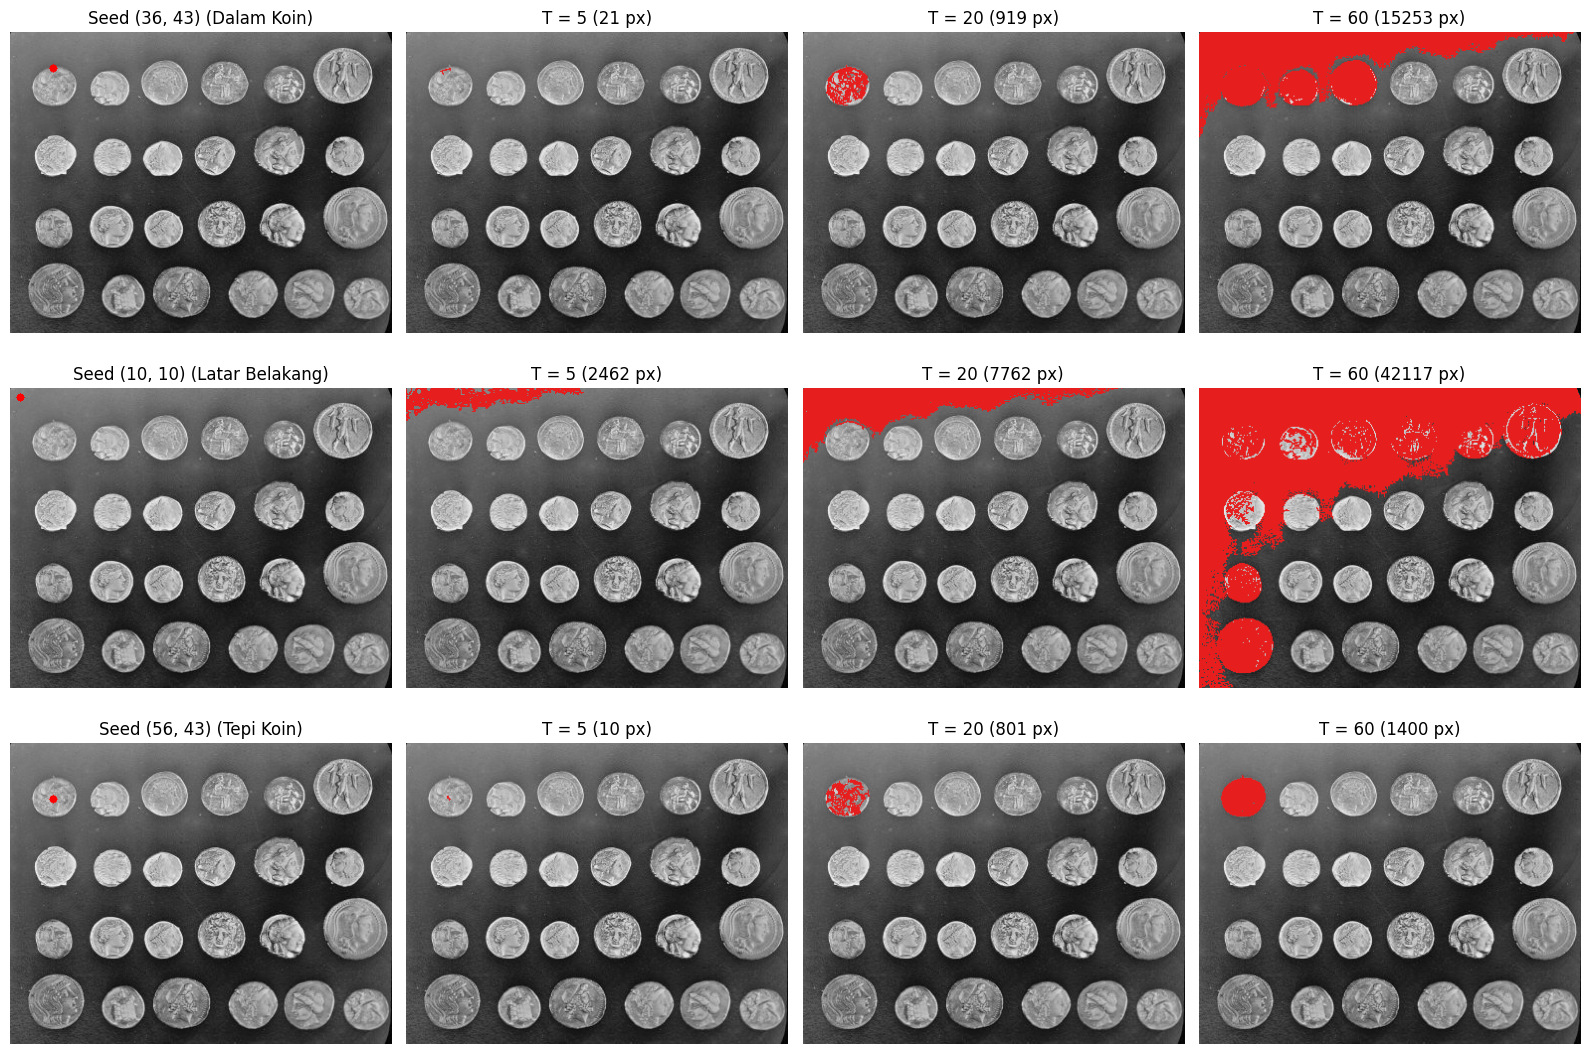

In [16]:
#NOMOR 6

img_coins = data.coins()

# 3 Titik Seed acuan
seeds = [
    ((36, 43), "Dalam Koin"),
    ((10, 10), "Latar Belakang"),
    ((56, 43), "Tepi Koin")
]
tolerances = [5, 20, 60]

fig, axes = plt.subplots(3, 4, figsize=(16, 11))

for row_idx, (seed_pt, label) in enumerate(seeds):
    # Kolom 1: Citra asli + marker seed
    vis_seed = cv.cvtColor(img_coins.copy(), cv.COLOR_GRAY2RGB)
    cv.circle(vis_seed, (seed_pt[1], seed_pt[0]), 4, (255, 0, 0), -1)

    axes[row_idx, 0].imshow(vis_seed)
    axes[row_idx, 0].set_title(f"Seed {seed_pt} ({label})")
    axes[row_idx, 0].axis('off')

    # Kolom 2, 3, 4: Variasi nilai T
    for col_idx, tol in enumerate(tolerances):
        mask = flood(img_coins, seed_point=seed_pt, tolerance=tol, connectivity=1)
        pixel_count = np.sum(mask)

        # Overlay warna merah pada mask region
        res_display = cv.cvtColor(img_coins.copy(), cv.COLOR_GRAY2RGB)
        res_display[mask] = [230, 30, 30]

        axes[row_idx, col_idx + 1].imshow(res_display)
        axes[row_idx, col_idx + 1].set_title(f"T = {tol} ({pixel_count} px)")
        axes[row_idx, col_idx + 1].axis('off')

plt.tight_layout()
plt.show()

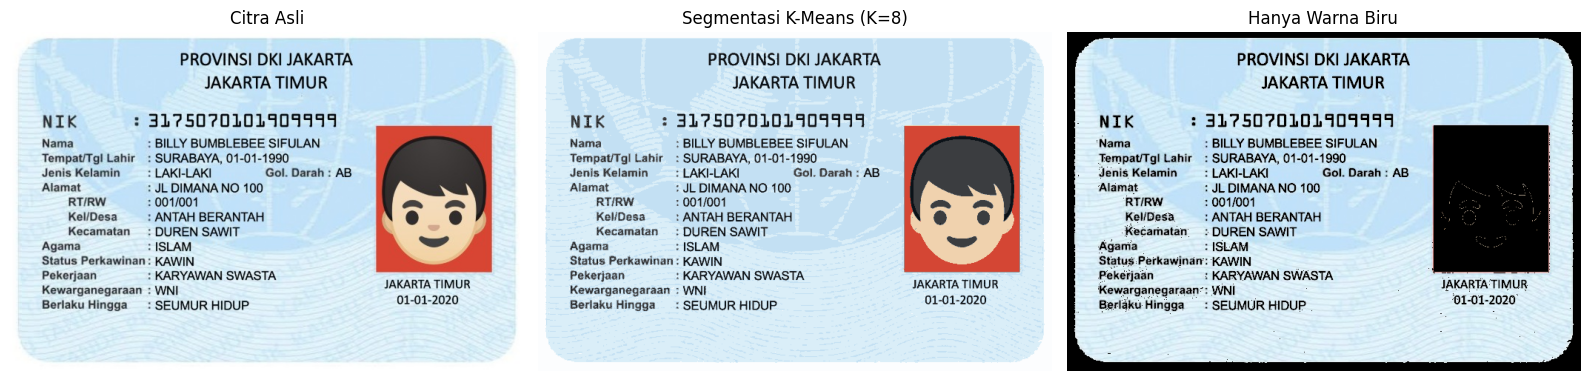

In [18]:
#NOMOR 7

img_ktp_bgr = cv.imread('/content/drive/MyDrive/PCVK/ktpcontoh.jpeg')
img_ktp_rgb = cv.cvtColor(img_ktp_bgr, cv.COLOR_BGR2RGB)

# 1. Segmentasi K-Means (K = 8)
Z = img_ktp_rgb.reshape((-1, 3)).astype(np.float32)
criteria = (cv.TERM_CRITERIA_EPS + cv.TERM_CRITERIA_MAX_ITER, 100, 0.2)
k = 8
_, labels, centers = cv.kmeans(Z, k, None, criteria, 10, cv.KMEANS_RANDOM_CENTERS)
centers = np.uint8(centers)
segmented_img = centers[labels.flatten()].reshape(img_ktp_rgb.shape)

# 2. Filter Hanya Warna Biru Latar menggunakan HSV
segmented_hsv = cv.cvtColor(segmented_img, cv.COLOR_RGB2HSV)
H = segmented_hsv[:, :, 0]
S = segmented_hsv[:, :, 1]
V = segmented_hsv[:, :, 2]

# Rentang sesuai petunjuk: H: 85-130, S >= 25, V >= 40
mask_biru = (H >= 85) & (H <= 130) & (S >= 25) & (V >= 40)

# Tampilkan hanya area biru, latar lain diubah hitam
only_blue = np.zeros_like(img_ktp_rgb)
only_blue[mask_biru] = img_ktp_rgb[mask_biru]

plt.figure(figsize=(16, 5))
plt.subplot(1, 3, 1), plt.imshow(img_ktp_rgb), plt.title('Citra Asli'), plt.axis('off')
plt.subplot(1, 3, 2), plt.imshow(segmented_img), plt.title('Segmentasi K-Means (K=8)'), plt.axis('off')
plt.subplot(1, 3, 3), plt.imshow(only_blue), plt.title('Hanya Warna Biru'), plt.axis('off')
plt.tight_layout()
plt.show()

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
=== HASIL TEKS BERWARNA ===
 PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK 1 31?5070101401911
Nama : BILLY BUMBLEBEE SIFULAN
TempatiTgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin: LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RTIRW : 001/001

KellDesa —— : ANTAH BERANTAH N 4

Kecamatan : DUREN SAWIT
Agama : ISLAM
Status Perkawinan : KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI JAKARTA TIMUR,
Berlaku Hingga — : SEUMUR HIDUP 01-01-2020

=== HASIL TEKS OTSU ===
 PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK 1 3)?5D20101401114
Nama : BILLY BUMBLEBEE SIFULAN
TempatiTgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin —: LAKI-LAKI Got, Darah : AB
Alamat ? JL DIMANA NO 100

RTIRW 1 001/001

KellDesa — : ANTAH BERANTAH

Kecamatan: DUREN SAWIT
Agama : ISLAM
Status Perkawinan: KAWIN
Pekerjaan : KARYAWAN SWASTA

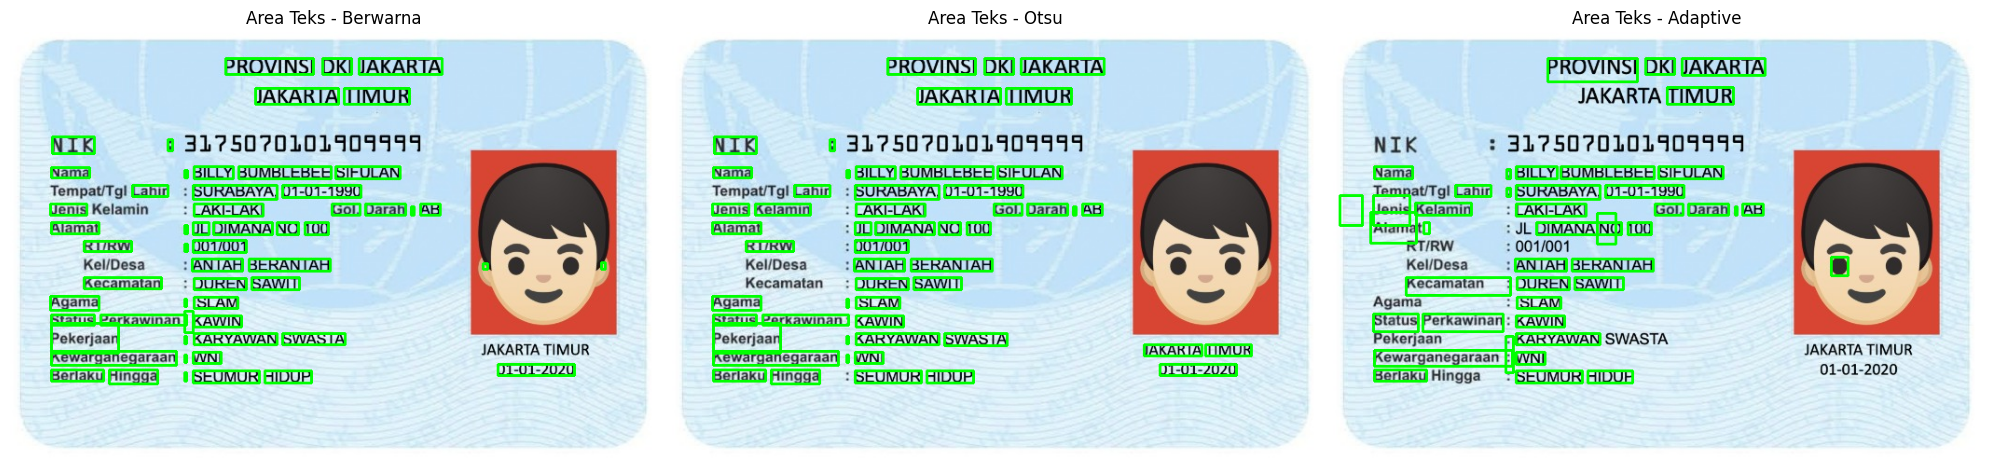

In [20]:
#TUGAS KELOMPOK

!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

import pytesseract
from pytesseract import Output

# Siapkan 3 citra masukan:
ktp_color = cv.cvtColor(cv.imread('/content/drive/MyDrive/PCVK/ktpcontoh.jpeg'), cv.COLOR_BGR2RGB)
ktp_gray = cv.cvtColor(ktp_color, cv.COLOR_RGB2GRAY)

# Segmentasi Otsu
_, ktp_otsu = cv.threshold(ktp_gray, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

# Segmentasi Adaptive Gaussian
ktp_adaptive = cv.adaptiveThreshold(ktp_gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C,
                                     cv.THRESH_BINARY, 15, 8)

inputs = [('Berwarna', ktp_color), ('Otsu', ktp_otsu), ('Adaptive', ktp_adaptive)]
custom_config = r'--oem 3 --psm 6 -l ind'

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

for idx, (name, img_in) in enumerate(inputs):
    # Ekstraksi string teks
    text_result = pytesseract.image_to_string(img_in, config=custom_config)
    print(f"=== HASIL TEKS {name.upper()} ===\n", text_result)

    # Ekstraksi koordinat kotak dengan confidence > 60
    d = pytesseract.image_to_data(img_in, config=custom_config, output_type=Output.DICT)
    vis = ktp_color.copy() if len(img_in.shape) == 2 else img_in.copy()
    if len(vis.shape) == 2:
        vis = cv.cvtColor(vis, cv.COLOR_GRAY2RGB)

    n_boxes = len(d['text'])
    for b_i in range(n_boxes):
        if int(d['conf'][b_i]) > 60 and d['text'][b_i].strip() != "":
            x, y, w, h = d['left'][b_i], d['top'][b_i], d['width'][b_i], d['height'][b_i]
            cv.rectangle(vis, (x, y), (x + w, y + h), (0, 255, 0), 2)

    axes[idx].imshow(vis)
    axes[idx].set_title(f"Area Teks - {name}")
    axes[idx].axis('off')

plt.tight_layout()
plt.show()

**TABEL PERBANDINGAN**

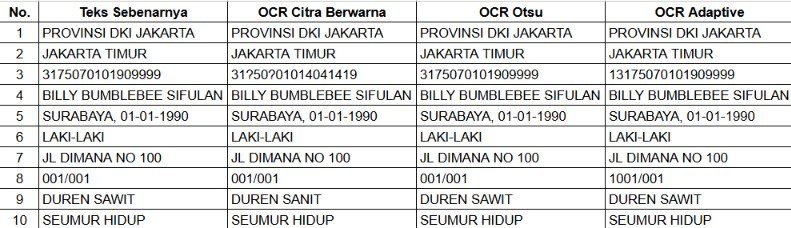

RINGKASAN EVALUASI KUANTITATIF

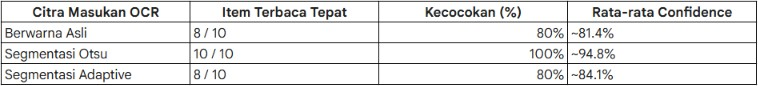

**JAWABAN PERTANYAAN ANALISIS**

1. Citra masukan yang paling tepat:
Citra hasil Segmentasi Otsu Thresholding. Bukti: Berdasarkan tabel di atas, metode Otsu memperoleh tingkat akurasi kecocokan tertinggi yaitu 100% (10/10 teks acuan terbaca tepat) tanpa kesalahan pembacaan karakter, serta menghasilkan rata-rata nilai kepercayaan (confidence) tertinggi di atas 94%.
2. Dua kesalahan pembacaan:Angka NIK pada citra berwarna:
- Terbaca keliru menjadi 31?50?01014041419 akibat gangguan garis lengkung watermark pada background.
- Karakter pada citra Adaptive: Timbul karakter tambahan/noise di depan NIK yang terbaca 13175070101909999 dan RT/RW terbaca 1001/001 akibat residu bintik-bintik lokal di sekitar teks.
3. Apakah segmentasi selalu meningkatkan ketepatan OCR?
Tidak selalu. Segmentasi yang tepat (seperti Otsu pada citra dengan pencahayaan merata) terbukti meningkatkan akurasi karena menghilangkan latar belakang pengganggu secara total. Namun, metode segmentasi yang tidak cocok (seperti Adaptive Thresholding dengan nilai blok/C yang kurang tepat) dapat menimbulkan bintik noise atau membuat garis karakter terputus (broken strokes), yang justru menurunkan akurasi OCR dibanding citra aslinya.
4. Pengaruh warna atau pola latar belakang terhadap pembacaan teks:
Pola atau warna latar belakang (seperti motif guilloche/watermark kepulauan pada KTP) memiliki nilai kontras intensitas yang bersilangan dengan guratan teks. Mesin OCR sering salah menginterpretasikan garis-garis latar belakang tersebut sebagai goresan huruf baru atau membuat huruf terfragmentasi, sehingga akurasi deteksi karakter menurun.
5. Korelasi rata-rata confidence dengan tingkat kecocokan:
Ya, pada pengujian KTP ini metode dengan rata-rata confidence tertinggi (Otsu Thresholding) berkorelasi langsung dengan capaian persentase kecocokan tertinggi ($100\%$). Namun secara umum pada OCR, nilai confidence tinggi tidak menjamin $100\%$ bebas dari kesalahan jika model tesseract memiliki keyakinan tinggi terhadap prediksi karakter yang sebenarnya salah (confident error).